In [1]:
%pip install -q "transformers==4.57.6" accelerate scipy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
# 1. Данные
import json
from pathlib import Path

import pandas as pd
from google.colab import drive

drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/Разметка')
if (ROOT / 'Разметка' / 'models.ipynb').is_file():
    ROOT /= 'Разметка'
DATA = ROOT / 'butterfly_detection-main' / 'data'
KEYS = ('left', 'width', 'top', 'height')

gold_path = ROOT / 'butterfly_golden_set_final.jsonl'
gold = [json.loads(line) for line in gold_path.read_text(encoding='utf-8-sig').splitlines() if line.strip()]
urls = pd.read_csv(DATA / 'bbox_input_all_400.csv', dtype=str).set_index('photo_id')['image_url']

photo_ids = [str(row['photo_id']) for row in gold]
if len(photo_ids) != 400 or len(urls) != 400 or set(photo_ids) != set(urls.index) or not urls.index.is_unique:
    raise ValueError('В golden set и CSV должны быть одни и те же 400 уникальных ID.')

image_urls = urls.loc[photo_ids].tolist()
gold_boxes = [[tuple(box[key] for key in KEYS) for box in row['boxes']] for row in gold]

Mounted at /content/drive


In [3]:
# 2. Общий прогон и оценка
# Эксперимент: меняется только порог уверенности. Ожидаем, что низкий порог повысит recall.
import hashlib
import io
import re
import time
from urllib.request import urlopen

import numpy as np
import torch
from huggingface_hub import model_info
from PIL import Image, ImageOps
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import maximum_bipartite_matching
from torchvision.ops import nms
from transformers import AutoModelForZeroShotObjectDetection, AutoProcessor, Qwen3VLForConditionalGeneration

IOU_THRESHOLD = .5
STRICT_IOU_THRESHOLD = .75
CONFIDENCE_THRESHOLDS = (.10, .15, .25, .35, .50)
OUT = ROOT / 'model_artifacts'
team_photos = dict(zip(photo_ids, image_urls))
gold_by_id = dict(zip(photo_ids, gold_boxes))
categories = pd.read_csv(DATA / 'metadata_all_400.csv', dtype=str).set_index('photo_id')['category']

if 'results' not in globals():
    results, group_results, tested_configs = {}, {}, {}

MODELS = {
    'dino': dict(id='IDEA-Research/grounding-dino-tiny', query='butterfly. moth.'),
    'owl': dict(id='google/owlv2-base-patch16-ensemble', query=['a photo of a butterfly', 'a photo of a moth']),
    'qwen': dict(id='Qwen/Qwen3-VL-2B-Instruct', query=(
        'Find all adult butterflies and adult moths. Draw one tight box around the visible wings, body, antennae and legs of each. '
        'Exclude other insects, caterpillars, pupae and shadows. Return only a JSON array with entries '
        '{"bbox_2d":[xmin,ymin,xmax,ymax],"label":"butterfly"}. Use coordinates from 0 to 1000 '
        'relative to the full image. Return [] when no target is present.'
    )),
}
MODELS = {name: dict(cfg, name=name, nms=.5, candidate_threshold=.05,
                     text_threshold=.25, max_new_tokens=1024, max_pixels=1048576)
          for name, cfg in MODELS.items()}
MODELS['qwen']['retry'] = dict(
    query=(
        'Detect the adult butterflies and moths visible in this image. '
        'Return a JSON array with one bbox_2d [xmin,ymin,xmax,ymax] per animal, '
        'using coordinates from 0 to 1000. Return [] if there are none.'
    ),
    max_side=768, max_new_tokens=512,
)


class QwenOutputError(ValueError):
    """Qwen сгенерировала текст, из которого нельзя получить корректный ответ."""


def load_model(cfg):
    """Загружает веса один раз и возвращает их настройки и функцию predict(image)."""
    cfg = cfg.copy()
    name = cfg['name']
    device = cfg.get('device') or ('cuda' if torch.cuda.is_available() else 'cpu')
    dtype = cfg.get('dtype', 'float16' if name == 'qwen' and device != 'cpu' else 'float32')
    cfg.update(device=device, dtype=dtype,
               revision=cfg.get('revision') or model_info(cfg['id'], token=False).sha)
    options = {'revision': cfg['revision'], 'token': False}
    processor_options = {'max_pixels': cfg['max_pixels']} if name == 'qwen' else {}
    processor = AutoProcessor.from_pretrained(cfg['id'], **options, **processor_options)
    model_class = Qwen3VLForConditionalGeneration if name == 'qwen' else AutoModelForZeroShotObjectDetection
    model = model_class.from_pretrained(cfg['id'], dtype=getattr(torch, dtype),
                                        use_safetensors=True, **options).to(device).eval()

    @torch.inference_mode()
    def predict(image):
        """Возвращает сырые рамки со scores или исходный JSON от Qwen."""
        if name == 'qwen':
            def generate(photo, prompt, limit):
                messages = [{'role': 'user', 'content': [
                    {'type': 'image', 'image': photo}, {'type': 'text', 'text': prompt},
                ]}]
                inputs = processor.apply_chat_template(
                    messages, tokenize=True, add_generation_prompt=True,
                    return_dict=True, return_tensors='pt',
                ).to(device, dtype=model.dtype)
                if 'pixel_values' not in inputs or 'image_grid_thw' not in inputs:
                    raise RuntimeError('Qwen не получила тензоры изображения.')
                tokens = model.generate(**inputs, do_sample=False, max_new_tokens=limit)
                return processor.batch_decode(tokens[:, inputs.input_ids.shape[1]:].cpu(),
                                              skip_special_tokens=True)[0]

            raw = generate(image, cfg['query'], cfg['max_new_tokens'])
            try:
                final_boxes(raw, cfg)
                return raw
            except (ValueError, TypeError, KeyError):
                retry = cfg['retry']
                small = image.copy()
                small.thumbnail((retry['max_side'], retry['max_side']))
                raw = generate(small, retry['query'], retry['max_new_tokens'])
                try:
                    final_boxes(raw, cfg)
                    return raw
                except (ValueError, TypeError, KeyError) as exc:
                    raise QwenOutputError(f'{exc}. Конец ответа: {raw[-300:]!r}') from exc
        text = cfg['query'] if name == 'dino' else [cfg['query']]
        inputs = processor(images=image, text=text, return_tensors='pt').to(device)
        outputs = model(**inputs)
        kwargs = dict(threshold=cfg['candidate_threshold'], target_sizes=[(image.height, image.width)])
        if name == 'dino':
            kwargs.update(input_ids=inputs.input_ids, text_threshold=cfg['text_threshold'])
        result = processor.post_process_grounded_object_detection(outputs, **kwargs)[0]
        size = [image.width, image.height] * 2
        coords = (result['boxes'].cpu() / torch.tensor(size)).clamp(0, 1).tolist()
        return [[x1, y1, x2, y2, score]
                for (x1, y1, x2, y2), score in zip(coords, result['scores'].cpu().tolist())
                if x2 > x1 and y2 > y1]

    return cfg, predict

def image_for(url):
    """Открывает фото в RGB и сохраняет скачанный оригинал в кэше."""
    path = OUT / 'images' / hashlib.sha256(url.encode()).hexdigest()
    if path.is_file():
        with Image.open(path) as image:
            return ImageOps.exif_transpose(image).convert('RGB')
    with urlopen(url, timeout=60) as response:
        data = response.read()
    with Image.open(io.BytesIO(data)) as image:
        rgb = ImageOps.exif_transpose(image).convert('RGB')
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(data)
    return rgb

def final_boxes(raw, cfg):
    """Превращает ответ модели в нормализованные рамки. Для детекторов применяет порог и NMS."""
    if cfg['name'] == 'qwen':
        text = re.sub(r'^```(?:json)?\s*|\s*```$', '', raw.strip(), flags=re.I)
        rows = json.loads(text)
        if isinstance(rows, dict):
            rows = [rows]
        if not isinstance(rows, list):
            raise ValueError('Ожидается рамка или список рамок.')
        if len(rows) == 4 and all(type(value) in (int, float) for value in rows):
            rows = [rows]  # Qwen иногда выдаёт одну рамку как [x1,y1,x2,y2].
        coords = [row['bbox_2d'] if isinstance(row, dict) else row for row in rows]
        if any(not isinstance(box, list) or len(box) != 4 or any(type(v) not in (int, float) or not 0 <= v <= 1000 for v in box)
               for box in coords):
            raise ValueError('Координаты Qwen должны быть в диапазоне 0–1000.')
        coords = [[v/1000 for v in box] for box in coords]
    else:
        candidates = [row for row in raw if row[4] >= cfg['threshold']]
        if not candidates:
            return []
        tensor = torch.tensor(candidates)
        keep = nms(tensor[:, :4], tensor[:, 4], cfg['nms']).tolist()
        coords = [candidates[i][:4] for i in keep]
    boxes = [dict(left=x1, width=x2-x1, top=y1, height=y2-y1) for x1, y1, x2, y2 in coords]
    if any(box['width'] <= 0 or box['height'] <= 0 for box in boxes):
        raise ValueError('Рамки должны иметь положительную ширину и высоту.')
    return boxes

def iou(a, b):
    """Вычисляет долю пересечения двух рамок в их объединении."""
    x, w, y, h = a
    u, p, v, q = b
    overlap = max(0, min(x+w, u+p)-max(x,u)) * max(0, min(y+h, v+q)-max(y,v))
    return overlap / (w*h + p*q - overlap)

def evaluate_model(name):
    """Прогоняет каждое фото один раз и проверяет пороги на тех же кандидатах."""
    cfg, predict = load_model(MODELS[name])
    thresholds = (None,) if name == 'qwen' else CONFIDENCE_THRESHOLDS
    if name != 'qwen' and min(thresholds) <= cfg['candidate_threshold']:
        raise ValueError('Пороги должны быть выше порога сохранения кандидатов.')
    configs = {threshold: dict(cfg, threshold=threshold) for threshold in thresholds}
    for threshold in thresholds:
        tested_configs.pop((name, threshold), None)
    rows, failures = [], {}
    predictions = {threshold: [] for threshold in thresholds}
    for i, (pid, url) in enumerate(team_photos.items(), 1):
        truth = gold_by_id[pid]
        try:
            with image_for(url) as image:
                started = time.perf_counter()
                raw = predict(image)
            elapsed = time.perf_counter() - started
            for threshold, current in configs.items():
                started = time.perf_counter()
                boxes = final_boxes(raw, current)
                seconds = elapsed + (time.perf_counter() - started)
                pred = [tuple(box[key] for key in KEYS) for box in boxes]
                tp = tp_075 = 0
                if pred and truth:
                    overlaps = np.array([[iou(a, b) for b in truth] for a in pred])
                    tp, tp_075 = (
                        int((maximum_bipartite_matching(csr_matrix(overlaps >= cutoff)) >= 0).sum())
                        for cutoff in (IOU_THRESHOLD, STRICT_IOU_THRESHOLD)
                    )
                predictions[threshold].append(
                    dict(photo_id=int(pid), photo_url=url, boxes=boxes, error=None)
                )
                rows.append(dict(confidence=threshold, category=categories.get(pid, 'unclassified'),
                                 TP=tp, TN=int(not truth and not pred), FP=len(pred)-tp, FN=len(truth)-tp,
                                 false_boxes=len(pred) if not truth else 0, seconds=seconds, errors=0,
                                 tp_iou_075=tp_075))
        except QwenOutputError as exc:
            failures[pid] = str(exc)
            predictions[None].append(
                dict(photo_id=int(pid), photo_url=url, boxes=None, error=failures[pid])
            )
            # Фото остаётся в оценке. Ошибка добавляет FN за эталонные рамки и не даёт TN.
            rows.append(dict(confidence=None, category=categories.get(pid, 'unclassified'),
                             TP=0, TN=0, FP=0, FN=len(truth), false_boxes=0,
                             seconds=time.perf_counter() - started, errors=1, tp_iou_075=0))
            print(f'qwen, photo_id={pid}: {exc}')
        except Exception as exc:
            raise RuntimeError(f'{name}, photo_id={pid}: {exc}') from exc
        if i % 50 == 0:
            print(name, f'{i}/{len(team_photos)}')

    prediction_dir = OUT / 'evaluation_predictions'
    prediction_dir.mkdir(parents=True, exist_ok=True)
    for threshold, records in predictions.items():
        filename = f'{name}.jsonl' if threshold is None else f'{name}_conf_{threshold:.2f}.jsonl'
        path = prediction_dir / filename
        temp_path = path.with_suffix('.tmp')
        with temp_path.open('w', encoding='utf-8') as file:
            for record in records:
                file.write(json.dumps(record, ensure_ascii=False, allow_nan=False) + '\n')
        temp_path.replace(path)
    print(f'Предсказания {name}: {prediction_dir}')

    frame = pd.DataFrame(rows)
    groups = pd.concat([frame, frame.assign(category='all')]).groupby(['category', 'confidence'], dropna=False)
    scores = groups[['TP', 'TN', 'FP', 'FN', 'false_boxes', 'errors']].sum()
    tp, fp, fn = scores['TP'], scores['FP'], scores['FN']
    scores = scores.assign(mean_seconds=groups['seconds'].mean(), precision=(tp/(tp+fp)).fillna(0),
                           recall=(tp/(tp+fn)).fillna(0), f1=(2*tp/(2*tp+fp+fn)).fillna(0))
    # Число предсказанных и эталонных рамок одинаково для обоих порогов IoU.
    scores['f1_iou_075'] = (2*groups['tp_iou_075'].sum() / (2*tp+fp+fn)).fillna(0)
    group_results[name] = scores.reset_index()
    results[name] = scores.loc['all'].reset_index().assign(model=name)
    if failures:
        print(f'{name}: {len(failures)} ошибок. F1 учитывает пропуски; конфигурация пока недоступна для Контеста.')
    else:
        tested_configs.update({(name, threshold): settings for threshold, settings in configs.items()})
    display(results[name])


In [4]:
# 3. GroundingDINO tiny
evaluate_model('dino')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/82.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/689M [00:00<?, ?B/s]

dino 50/400
dino 100/400
dino 150/400
dino 200/400
dino 250/400
dino 300/400
dino 350/400
dino 400/400
Предсказания dino: /content/drive/MyDrive/Разметка/model_artifacts/evaluation_predictions


,confidence,TP,TN,FP,FN,false_boxes,errors,mean_seconds,precision,recall,f1,f1_iou_075,model
0,0.10,332,0,807,9,421,0,0.519040,0.291484,0.973607,0.448649,0.379730,dino
1,0.15,329,0,485,12,293,0,0.518973,0.404177,0.964809,0.569697,0.483117,dino
2,0.25,325,0,238,16,178,0,0.518941,0.577265,0.953079,0.719027,0.612832,dino
3,0.35,306,2,146,35,124,0,0.518923,0.676991,0.897361,0.771753,0.673392,dino
4,0.50,94,64,27,247,24,0,0.518807,0.776860,0.275660,0.406926,0.376623,dino


In [5]:
# 4. OWLv2 base
evaluate_model('owl')

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/620M [00:00<?, ?B/s]

owl 50/400
owl 100/400
owl 150/400
owl 200/400
owl 250/400
owl 300/400
owl 350/400
owl 400/400
Предсказания owl: /content/drive/MyDrive/Разметка/model_artifacts/evaluation_predictions


,confidence,TP,TN,FP,FN,false_boxes,errors,mean_seconds,precision,recall,f1,f1_iou_075,model
0,0.10,313,8,910,28,316,0,1.126039,0.255928,0.917889,0.400256,0.248082,owl
1,0.15,308,12,558,33,216,0,1.125979,0.355658,0.903226,0.510356,0.321458,owl
2,0.25,302,33,305,39,139,0,1.125928,0.497529,0.885630,0.637131,0.405063,owl
3,0.35,292,49,161,49,84,0,1.125914,0.644592,0.856305,0.735516,0.468514,owl
4,0.50,275,69,56,66,26,0,1.125902,0.830816,0.806452,0.818452,0.529762,owl


In [6]:
# 5. Qwen3-VL-2B-Instruct
evaluate_model('qwen')

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

... (3 outputs left out)

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


qwen 50/400
qwen 100/400
qwen 150/400
qwen 200/400
qwen 250/400
qwen, photo_id=762560238: Unterminated string starting at: line 15 column 45 (char 1030). Конец ответа: 't butterflies and moths"},\n\t{"bbox_2d": [234, 385, 290, 445], "label": "adult butterflies and moths"},\n\t{"bbox_2d": [258, 265, 338, 335], "label": "adult butterflies and moths"},\n\t{"bbox_2d": [258, 245, 338, 305], "label": "adult butterflies and moths"},\n\t{"bbox_2d": [338, 295, 428, 365], "label": "'
qwen 300/400
qwen 350/400
qwen 400/400
Предсказания qwen: /content/drive/MyDrive/Разметка/model_artifacts/evaluation_predictions
qwen: 1 ошибок. F1 учитывает пропуски; конфигурация пока недоступна для Контеста.


,confidence,TP,TN,FP,FN,false_boxes,errors,mean_seconds,precision,recall,f1,f1_iou_075,model
0,NaN,327,3,84,14,78,1,4.612237,0.79562,0.958944,0.869681,0.75,qwen


,model,confidence,TP,TN,FP,FN,precision,recall,f1,f1_iou_075,mean_seconds
10,qwen,NaN,327,3,84,14,0.795620,0.958944,0.869681,0.750000,4.612237
9,owl,0.50,275,69,56,66,0.830816,0.806452,0.818452,0.529762,1.125902
3,dino,0.35,306,2,146,35,0.676991,0.897361,0.771753,0.673392,0.518923
8,owl,0.35,292,49,161,49,0.644592,0.856305,0.735516,0.468514,1.125914
2,dino,0.25,325,0,238,16,0.577265,0.953079,0.719027,0.612832,0.518941
7,owl,0.25,302,33,305,39,0.497529,0.885630,0.637131,0.405063,1.125928
1,dino,0.15,329,0,485,12,0.404177,0.964809,0.569697,0.483117,0.518973
6,owl,0.15,308,12,558,33,0.355658,0.903226,0.510356,0.321458,1.125979
0,dino,0.10,332,0,807,9,0.291484,0.973607,0.448649,0.379730,0.519040
4,dino,0.50,94,64,27,247,0.776860,0.275660,0.406926,0.376623,0.518807


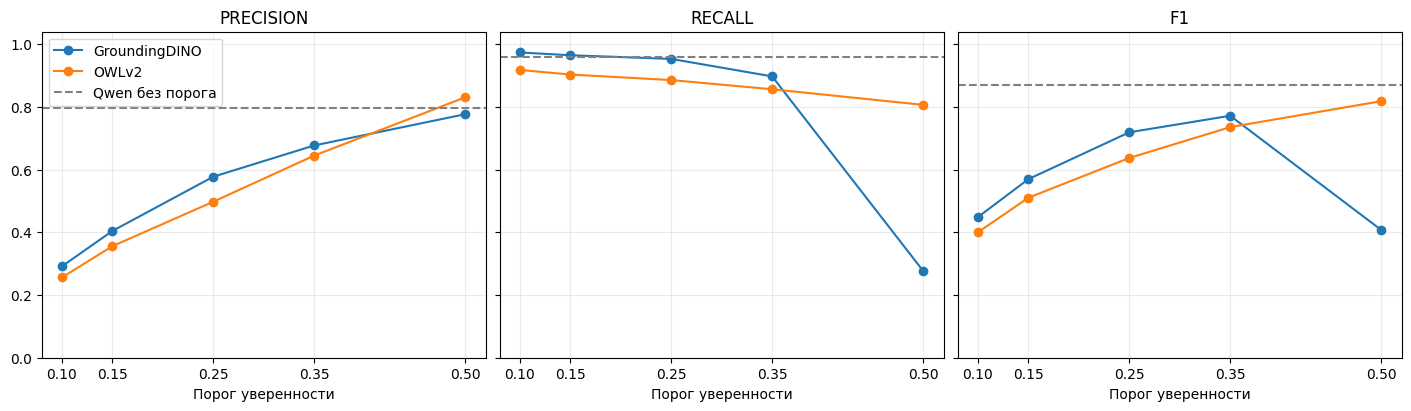

In [7]:
# 6. Перебор порогов уверенности. Графики при IoU 0.5, дополнительный F1 при 0.75 в таблице.
import matplotlib.pyplot as plt

comparison = pd.concat([results[name] for name in MODELS], ignore_index=True)
display(comparison.sort_values(['f1', 'mean_seconds'], ascending=[False, True])
        [['model', 'confidence', 'TP', 'TN', 'FP', 'FN', 'precision', 'recall', 'f1', 'f1_iou_075', 'mean_seconds']])
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True, layout='constrained')
for ax, metric in zip(axes, ('precision', 'recall', 'f1')):
    for name, label in [('dino', 'GroundingDINO'), ('owl', 'OWLv2')]:
        points = results[name].sort_values('confidence')
        ax.plot(points['confidence'], points[metric], 'o-', label=label)
    ax.axhline(results['qwen'][metric].iloc[0], ls='--', color='gray', label='Qwen без порога')
    ax.set(title=metric.upper(), xlabel='Порог уверенности', xticks=CONFIDENCE_THRESHOLDS, ylim=(0, 1.04))
    ax.grid(alpha=.25)
axes[0].legend()
plt.show()

In [ ]:
# 7. Контест: впиши модель и порог из таблицы. Для Qwen порог всегда None.
CONTEST_MODEL = 'owl'  # 'dino', 'owl' или 'qwen'
CONTEST_CONFIDENCE = 0.5  # Число из таблицы для dino/owl, None для qwen

def contest_urls(path):
    """Читает 400 уникальных ID и ссылки из официального JSONL."""
    rows = [json.loads(line) for line in path.read_text(encoding='utf-8-sig').splitlines()]
    if any(type(row['photo_id']) is not int or not row['photo_url'].startswith('https://') for row in rows):
        raise ValueError(f'{path.name}: проверь photo_id и photo_url.')
    photos = {str(row['photo_id']): row['photo_url'] for row in rows}
    if len(rows) != 400 or len(photos) != 400:
        raise ValueError(f'{path.name}: нужно ровно 400 уникальных ID.')
    return photos

if CONTEST_MODEL is not None:
    choice = (CONTEST_MODEL, CONTEST_CONFIDENCE)
    if choice not in tested_configs:
        raise ValueError('Выбери модель и порог из таблицы сравнения.')
    photos = contest_urls(ROOT / 'dataset.jsonl')
    if photos.keys() & team_photos.keys() or set(photos.values()) & set(team_photos.values()):
        raise ValueError('Набор Контеста пересекается с фото команды.')
    template_path = ROOT / 'submission-template.jsonl'
    template = contest_urls(template_path) if template_path.is_file() else photos
    if template != photos:
        raise ValueError('Шаблон должен совпадать с dataset.jsonl по ID и ссылкам.')

    cfg, predict = load_model(tested_configs[choice])
    lines = []
    for pid, url in template.items():
        try:
            with image_for(url) as image:
                boxes = final_boxes(predict(image), cfg)
        except Exception as exc:
            raise RuntimeError(f'Контест, photo_id={pid}: {exc}') from exc
        record = dict(photo_id=int(pid), photo_url=url, boxes=boxes, error=None)
        lines.append(json.dumps(record, allow_nan=False, separators=(',', ':')))
    content = ('\n'.join(lines) + '\n').encode('utf-8')
    if len(content) > 5 * 1024**2:
        raise ValueError('Файл больше 5 МиБ.')
    OUT.mkdir(exist_ok=True)
    (OUT / 'selection.json').write_text(json.dumps(cfg, indent=2), encoding='utf-8')
    submission = OUT / 'submission.jsonl'
    submission.write_bytes(content)
    print(f'{submission} — {len(lines)} строк.')

/content/drive/MyDrive/Разметка/model_artifacts/submission.jsonl — 400 строк.
